<a href="https://colab.research.google.com/github/ShriNithee/waste-bin-classifier/blob/main/waste_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ♻️ Waste Classifier: Which Bin Does It Go In?

This notebook trains an image model that looks at a photo of a waste item, figures out **what** it is (plastic, paper, food waste, battery...), and tells you **which bin** it belongs in.

**How to use this notebook (beginner guide):**
1. Open it in [Google Colab](https://colab.research.google.com) (File → Upload notebook).
2. Turn on the free GPU: **Runtime → Change runtime type → T4 GPU**.
3. Run each cell one by one from top to bottom with **Shift + Enter**. Read the text above each cell to understand what it does.

**The big idea: transfer learning.** Instead of teaching a model to see from scratch (which needs millions of images), we take **MobileNetV2**, a model already trained on 1.4 million everyday images, and just teach its last layer to recognise waste. This is fast, works on a free GPU, and gives good accuracy.

## Step 1: Import libraries and check the GPU

- **TensorFlow / Keras**: the deep learning library we use to build and train the model.
- **NumPy**: for working with numbers and arrays.
- **Matplotlib**: for drawing charts and showing images.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print("GPU available:", bool(gpus))
if not gpus:
    print("⚠️ No GPU found. Go to Runtime → Change runtime type → T4 GPU, then run again.")

TensorFlow version: 2.21.0
GPU available: True


## Step 2: Download the dataset

We use the **Garbage Classification (12 classes)** dataset from Kaggle: about 15,000 photos in 12 categories:

`paper, cardboard, biological, metal, plastic, green-glass, brown-glass, white-glass, clothes, shoes, batteries, trash`

The `kagglehub` library downloads it for us. Each category is stored in its own folder, and the folder name is the label. That's all a classifier needs.

*If it asks you to log in:* create a free Kaggle account, go to Settings → API → Create New Token, and follow the prompt.

In [2]:
!pip install -q kagglehub
import kagglehub

download_path = kagglehub.dataset_download("mostafaabla/garbage-classification")
print("Downloaded to:", download_path)

# Find the folder that contains the class sub-folders (the one with 'biological' inside it)
DATA_DIR = None
for root, dirs, files in os.walk(download_path):
    if 'biological' in dirs and 'plastic' in dirs:
        DATA_DIR = root
        break
print("Data folder:", DATA_DIR)

# Count images in each class
print("\nImages per class:")
for cls in sorted(os.listdir(DATA_DIR)):
    print(f"  {cls:12s} {len(os.listdir(os.path.join(DATA_DIR, cls)))}")

Using Colab cache for faster access to the 'garbage-classification' dataset.
Downloaded to: /kaggle/input/garbage-classification
Data folder: /kaggle/input/garbage-classification/garbage_classification

Images per class:
  battery      945
  biological   985
  brown-glass  607
  cardboard    891
  clothes      5325
  green-glass  629
  metal        769
  paper        1050
  plastic      865
  shoes        1977
  trash        697
  white-glass  775


## Step 3: Map each waste type to a bin

The model predicts the **waste type**. This dictionary then converts that into the **bin** to use, following India's Solid Waste Management Rules, which ask households to separate waste into wet, dry and domestic hazardous.

You can edit this mapping to match your city's rules, since it's just a Python dictionary.

In [3]:
BIN_MAP = {
    'biological':  ('🟢 GREEN bin – Wet waste',            'Food scraps and organic matter. Can be composted.'),
    'paper':       ('🔵 BLUE bin – Dry recyclable',        'Keep it dry and clean so it can be recycled.'),
    'cardboard':   ('🔵 BLUE bin – Dry recyclable',        'Flatten boxes before disposing.'),
    'plastic':     ('🔵 BLUE bin – Dry recyclable',        'Rinse food containers before disposing.'),
    'metal':       ('🔵 BLUE bin – Dry recyclable',        'Cans and tins are valuable to scrap dealers.'),
    'green-glass': ('🔵 BLUE bin – Dry recyclable',        'Wrap broken glass in paper to protect waste workers.'),
    'brown-glass': ('🔵 BLUE bin – Dry recyclable',        'Wrap broken glass in paper to protect waste workers.'),
    'white-glass': ('🔵 BLUE bin – Dry recyclable',        'Wrap broken glass in paper to protect waste workers.'),
    'clothes':     ('🔵 BLUE bin – Dry waste',             'If still usable, donate instead of throwing away.'),
    'shoes':       ('🔵 BLUE bin – Dry waste',             'If still usable, donate instead of throwing away.'),
    'battery':   ('🔴 RED bin – Domestic hazardous',     'Never mix with regular waste. Give to e-waste collection.'),
    'trash':       ('⚫ BLACK bin – Non-recyclable reject', 'Mixed or soiled items that cannot be recycled.'),
}

for k, (b, tip) in BIN_MAP.items():
    print(f"{k:12s} → {b}")

biological   → 🟢 GREEN bin – Wet waste
paper        → 🔵 BLUE bin – Dry recyclable
cardboard    → 🔵 BLUE bin – Dry recyclable
plastic      → 🔵 BLUE bin – Dry recyclable
metal        → 🔵 BLUE bin – Dry recyclable
green-glass  → 🔵 BLUE bin – Dry recyclable
brown-glass  → 🔵 BLUE bin – Dry recyclable
white-glass  → 🔵 BLUE bin – Dry recyclable
clothes      → 🔵 BLUE bin – Dry waste
shoes        → 🔵 BLUE bin – Dry waste
battery      → 🔴 RED bin – Domestic hazardous
trash        → ⚫ BLACK bin – Non-recyclable reject


## Step 4: Load the images and split into training and validation sets

- **Training set (80%)**: images the model learns from.
- **Validation set (20%)**: images the model **never** sees during training. We use them to check how well it really works on new photos.

All images are resized to **224 × 224 pixels** because that's the size MobileNetV2 expects. They're fed in **batches of 32** at a time.

In [4]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.2, subset='training', seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='int')

val_ds = keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.2, subset='validation', seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='int')

CLASS_NAMES = train_ds.class_names
NUM_CLASSES = len(CLASS_NAMES)
print("Classes:", CLASS_NAMES)

# Makes training faster by preparing the next batch while the GPU works on the current one
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

Found 15515 files belonging to 12 classes.
Using 12412 files for training.
Found 15515 files belonging to 12 classes.
Using 3103 files for validation.
Classes: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']


## Step 5: Look at some example images

Always look at your data before training. It helps you spot problems like wrong labels or blurry images.

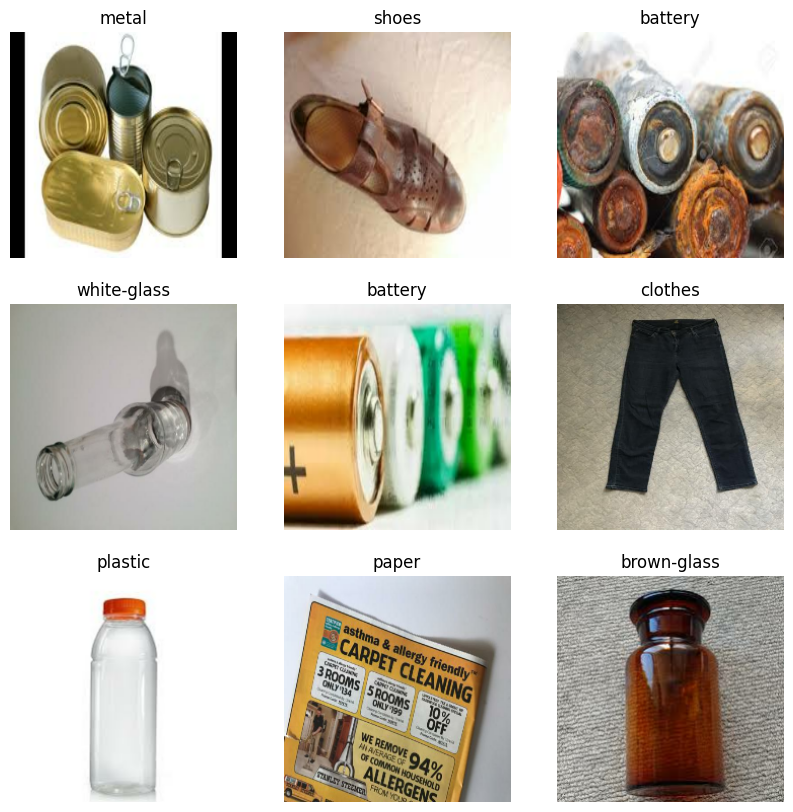

In [5]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(CLASS_NAMES[labels[i]])
        plt.axis('off')
plt.show()

## Step 6: Build the model

The model has four parts, stacked like layers of a cake:

1. **Data augmentation**: randomly flips, rotates and zooms training images so the model learns that a bottle is still a bottle from any angle. This reduces *overfitting* (memorising instead of learning).
2. **Preprocessing**: scales pixel values into the range MobileNetV2 was trained on.
3. **MobileNetV2 base (frozen)**: the pretrained part that already knows how to detect edges, textures and shapes. *Frozen* means we don't change its weights yet.
4. **Our classifier head**: a small new layer that learns to map those features to our 12 waste types.

In [6]:
data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name='augmentation')

base_model = keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,), include_top=False, weights='imagenet')
base_model.trainable = False  # freeze the pretrained part

inputs = keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)  # randomly switches off 30% of connections to reduce overfitting
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 12)             │        15,372 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 2,273,356 (8.67 MB)

Trainable params: 15,372 (60.05 KB)

Non-trainable params: 2,257,984 (8.61 MB)

## Step 7: Train the model

An **epoch** is one full pass over all training images. We train for 5 epochs. Watch two numbers:

- `accuracy`: how well it does on training images
- `val_accuracy`: how well it does on **unseen** images (this is the one that matters)

This takes roughly 5–10 minutes on a Colab T4 GPU.

In [8]:
INITIAL_EPOCHS = 5
history = model.fit(train_ds, validation_data=val_ds, epochs=INITIAL_EPOCHS)

Epoch 1/5
388/388 ━━━━━━━━━━━━━━━━━━━━ 34s 89ms/step - accuracy: 0.9293 - loss: 0.2061 - val_accuracy: 0.9388 - val_loss: 0.1842
Epoch 2/5
388/388 ━━━━━━━━━━━━━━━━━━━━ 33s 68ms/step - accuracy: 0.9320 - loss: 0.2069 - val_accuracy: 0.9433 - val_loss: 0.1772
Epoch 3/5
388/388 ━━━━━━━━━━━━━━━━━━━━ 41s 69ms/step - accuracy: 0.9306 - loss: 0.2031 - val_accuracy: 0.9426 - val_loss: 0.1722
Epoch 4/5
388/388 ━━━━━━━━━━━━━━━━━━━━ 27s 71ms/step - accuracy: 0.9365 - loss: 0.1898 - val_accuracy: 0.9388 - val_loss: 0.1780
Epoch 5/5
388/388 ━━━━━━━━━━━━━━━━━━━━ 40s 69ms/step - accuracy: 0.9381 - loss: 0.1840 - val_accuracy: 0.9359 - val_loss: 0.1884


## Step 8: Fine-tune for better accuracy

Now we **unfreeze the top layers** of MobileNetV2 and train a bit more with a **very small learning rate**. This gently adjusts the pretrained features to suit waste images specifically. A small learning rate matters, because big changes would destroy what the model already knows.

This step usually adds a few percent of accuracy.

In [9]:
base_model.trainable = True
for layer in base_model.layers[:-40]:  # keep all but the last 40 layers frozen
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])

FINE_TUNE_EPOCHS = 5
history_fine = model.fit(
    train_ds, validation_data=val_ds,
    epochs=INITIAL_EPOCHS + FINE_TUNE_EPOCHS,
    initial_epoch=INITIAL_EPOCHS)

Epoch 6/10
388/388 ━━━━━━━━━━━━━━━━━━━━ 47s 93ms/step - accuracy: 0.8824 - loss: 0.3557 - val_accuracy: 0.9381 - val_loss: 0.1824
Epoch 7/10
388/388 ━━━━━━━━━━━━━━━━━━━━ 35s 91ms/step - accuracy: 0.9193 - loss: 0.2487 - val_accuracy: 0.9420 - val_loss: 0.1770
Epoch 8/10
388/388 ━━━━━━━━━━━━━━━━━━━━ 36s 92ms/step - accuracy: 0.9267 - loss: 0.2239 - val_accuracy: 0.9439 - val_loss: 0.1693
Epoch 9/10
388/388 ━━━━━━━━━━━━━━━━━━━━ 36s 93ms/step - accuracy: 0.9336 - loss: 0.1957 - val_accuracy: 0.9468 - val_loss: 0.1653
Epoch 10/10
388/388 ━━━━━━━━━━━━━━━━━━━━ 36s 93ms/step - accuracy: 0.9385 - loss: 0.1850 - val_accuracy: 0.9491 - val_loss: 0.1568


## Step 9: Plot the learning curves

If training accuracy keeps rising but validation accuracy stays flat or drops, the model is **overfitting**. Ideally both lines rise together. The dashed line marks where fine-tuning started.

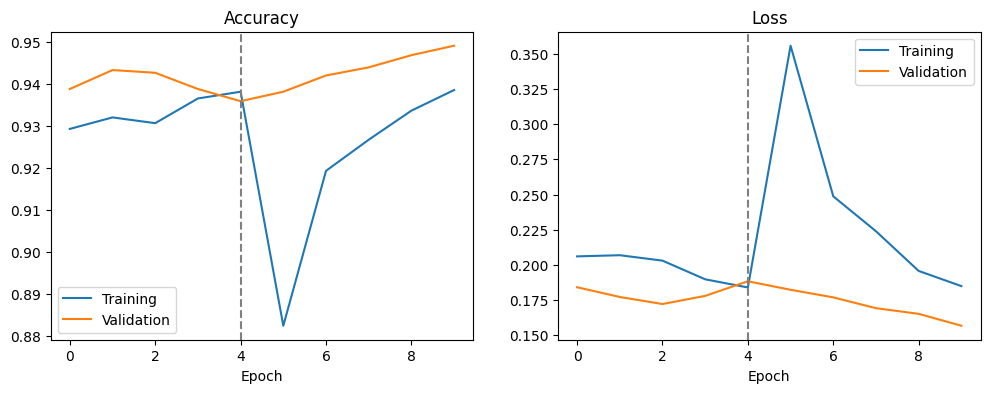

In [10]:
acc = history.history['accuracy'] + history_fine.history['accuracy']
val_acc = history.history['val_accuracy'] + history_fine.history['val_accuracy']
loss = history.history['loss'] + history_fine.history['loss']
val_loss = history.history['val_loss'] + history_fine.history['val_loss']

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Training')
plt.plot(val_acc, label='Validation')
plt.axvline(INITIAL_EPOCHS - 1, linestyle='--', color='gray')
plt.title('Accuracy'); plt.xlabel('Epoch'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label='Training')
plt.plot(val_loss, label='Validation')
plt.axvline(INITIAL_EPOCHS - 1, linestyle='--', color='gray')
plt.title('Loss'); plt.xlabel('Epoch'); plt.legend()
plt.show()

## Step 10: Evaluate properly

Accuracy alone can hide problems, so we also look at:

- **Classification report**: precision and recall for each class. Low recall for `batteries` would be serious, because hazardous waste going into the wrong bin is the worst mistake.
- **Confusion matrix**: shows which classes get mixed up (for example, white-glass vs plastic).
- **Bin-level accuracy**: what users actually care about. Confusing paper with cardboard doesn't matter, since both go in the blue bin.

These numbers go straight into your project report.

Waste-type accuracy: 94.91 %
Bin-level accuracy:  98.78 %

              precision    recall  f1-score   support

     battery       0.97      0.99      0.98       180
  biological       0.98      0.97      0.98       195
 brown-glass       0.92      0.92      0.92       111
   cardboard       0.93      0.95      0.94       176
     clothes       0.99      0.99      0.99      1065
 green-glass       0.92      0.96      0.94       122
       metal       0.77      0.93      0.84       145
       paper       0.95      0.87      0.91       218
     plastic       0.91      0.81      0.86       189
       shoes       0.96      0.98      0.97       407
       trash       0.97      0.97      0.97       143
 white-glass       0.87      0.82      0.84       152

    accuracy                           0.95      3103
   macro avg       0.93      0.93      0.93      3103
weighted avg       0.95      0.95      0.95      3103



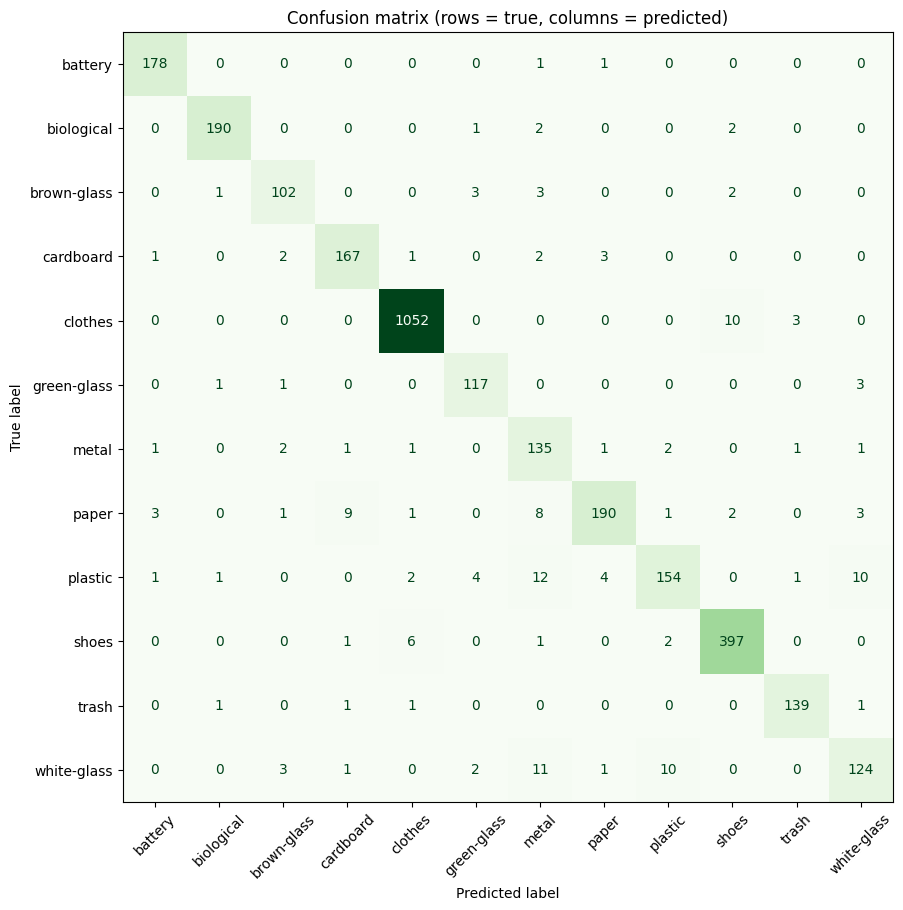

In [11]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_true, y_pred = [], []
for images, labels in val_ds:
    probs = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(probs, axis=1))
y_true, y_pred = np.array(y_true), np.array(y_pred)

print("Waste-type accuracy:", round((y_true == y_pred).mean() * 100, 2), "%")

bin_true = [BIN_MAP[CLASS_NAMES[i]][0] for i in y_true]
bin_pred = [BIN_MAP[CLASS_NAMES[i]][0] for i in y_pred]
print("Bin-level accuracy: ", round(np.mean(np.array(bin_true) == np.array(bin_pred)) * 100, 2), "%\n")

print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=CLASS_NAMES).plot(
    ax=ax, xticks_rotation=45, cmap='Greens', colorbar=False)
plt.title('Confusion matrix (rows = true, columns = predicted)')
plt.show()

## Step 11: Try it on your own photo 📸

Run the cell, click **Choose Files**, and upload a photo of any waste item (take one with your phone!). The model tells you what it is, which bin to use, and how confident it is.

If confidence is low (below 60%), the app says it's unsure instead of guessing. That's an important safety feature for a real app.

Saving Screenshot 2026-10-26 220034.png to Screenshot 2026-10-26 220034.png


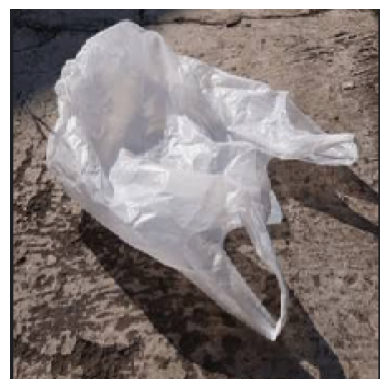

Detected: plastic  (68% confident)
Dispose in: 🔵 BLUE bin – Dry recyclable
Tip: Rinse food containers before disposing.

Top 3 guesses: plastic 68%, trash 30%, clothes 1%


In [13]:
from google.colab import files

def predict_bin(img_path, threshold=0.60):
    img = keras.utils.load_img(img_path, target_size=IMG_SIZE)
    arr = np.expand_dims(keras.utils.img_to_array(img), 0)
    probs = model.predict(arr, verbose=0)[0]
    top3 = np.argsort(probs)[::-1][:3]

    plt.imshow(img); plt.axis('off'); plt.show()
    best = CLASS_NAMES[top3[0]]
    conf = probs[top3[0]]
    if conf < threshold:
        print(f"🤔 Not sure (best guess: {best}, {conf:.0%}). Try a clearer photo of a single item.")
    else:
        bin_name, tip = BIN_MAP[best]
        print(f"Detected: {best}  ({conf:.0%} confident)")
        print(f"Dispose in: {bin_name}")
        print(f"Tip: {tip}")
    print("\nTop 3 guesses:", ", ".join(f"{CLASS_NAMES[i]} {probs[i]:.0%}" for i in top3))

uploaded = files.upload()
for name in uploaded:
    predict_bin(name)

## Step 12: Save the trained model

This saves the model and the class names so you can load them later inside your Django web app, without retraining. The files download to your computer.

In [14]:
import json

model.save('waste_classifier.keras')
with open('class_names.json', 'w') as f:
    json.dump(CLASS_NAMES, f)

files.download('waste_classifier.keras')
files.download('class_names.json')

## ✅ What you've built, and what's next

You now have a working waste classifier using transfer learning. Ideas to improve it and grow it into your full project:

1. **Test on real Indian waste**: photograph 50–100 items around your home or campus (milk packets, coconut shells, chips wrappers) and check accuracy. This *real-world test set* will impress evaluators.
2. **Add missing classes**: e-waste, sanitary waste, multi-layer packaging. Collect your own photos into new folders and retrain.
3. **Compare models**: try `EfficientNetB0` or `ResNet50` in place of MobileNetV2 and compare accuracy and speed in a table for your report.
4. **Wrap it in a web app**: load `waste_classifier.keras` in Django and let users upload a photo from their phone.
5. **Move to object detection (YOLOv8)**: later, for the black-spot platform, you'll detect garbage *within* a scene instead of classifying a single item.